# 01 · Exploración del Titanic con MLflow
Exploramos el dataset y dejamos registrada la exploración como un run en MLflow.

In [1]:
import sys
from pathlib import Path

# Raíz del proyecto: funciona aunque Jupyter se abra desde notebooks/ o desde la raíz
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(RAIZ / "src"))

import mlflow
mlflow.set_tracking_uri(f"sqlite:///{RAIZ / 'mlflow.db'}")   # misma base que usa la interfaz y train.py
mlflow.set_experiment("clasificacion-titanic")

from data import cargar_dataframe, cargar_datos
df = cargar_dataframe()
df.head()

2026/11/08 14:47:40 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/08 14:47:40 INFO mlflow.store.db.utils: Updating database tables
2026/11/08 14:47:52 INFO mlflow.tracking.fluent: Experiment with name 'clasificacion-titanic' does not exist. Creating a new experiment.


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Estructura de los datos

In [2]:
print(df.shape)
df.info()

(891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [3]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 2. Valores nulos
`Age`, `Cabin` y `Embarked` tienen datos faltantes. El pipeline de `src/train.py` imputa `Age` y `Embarked`; `Cabin` no se usa.

In [4]:
nulos = df.isnull().sum()
nulos[nulos > 0]

Age         177
Cabin       687
Embarked      2
dtype: int64

## 3. Supervivencia por variable

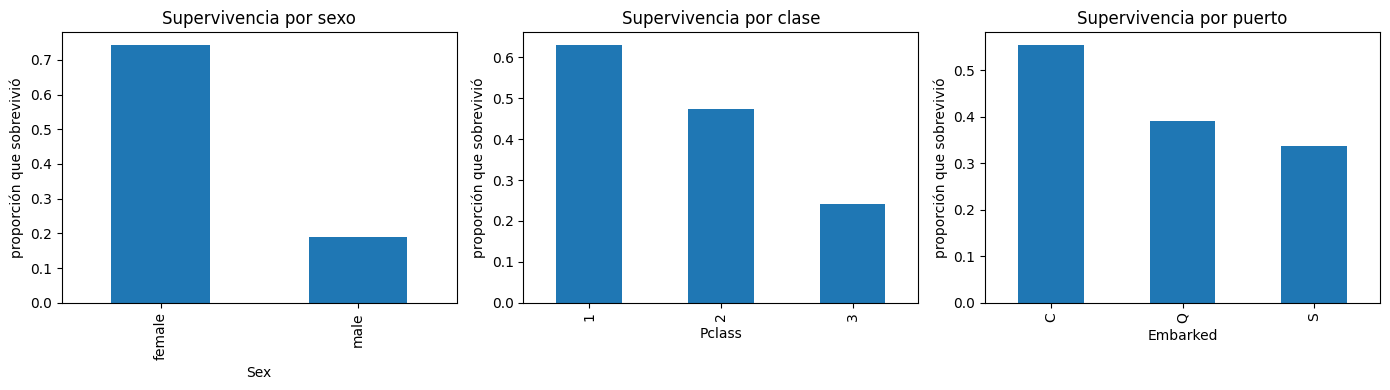

In [5]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
df.groupby("Sex")["Survived"].mean().plot.bar(ax=ejes[0], title="Supervivencia por sexo")
df.groupby("Pclass")["Survived"].mean().plot.bar(ax=ejes[1], title="Supervivencia por clase")
df.groupby("Embarked")["Survived"].mean().plot.bar(ax=ejes[2], title="Supervivencia por puerto")
for e in ejes:
    e.set_ylabel("proporción que sobrevivió")
plt.tight_layout()
plt.show()

In [6]:
df["Survived"].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

## 4. Registrar la exploración en MLflow
Guardamos el dataset (con su huella) y el gráfico en un run.

In [7]:
X_train, X_test, y_train, y_test = cargar_datos()

dataset = mlflow.data.from_pandas(
    df,
    source="data/Titanic-Dataset.csv",
    name="titanic",
    targets="Survived",
)

with mlflow.start_run(run_name="exploracion"):
    mlflow.log_input(dataset, context="exploracion")
    mlflow.log_params({"filas": len(df), "columnas": df.shape[1], "test_size": 0.3, "seed": 42})
    mlflow.log_metric("tasa_supervivencia", df["Survived"].mean())
    mlflow.log_figure(fig, "supervivencia_por_variable.png")
    mlflow.set_tags({"etapa": "exploracion", "dataset": "titanic"})

C:\Users\Asus-PC\Downloads\modulo6\.venv\lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
C:\Users\Asus-PC\Downloads\modulo6\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <ht

## 5. Prueba rápida de un modelo
Para el entrenamiento completo se usa `python src/train.py` desde la terminal.

In [8]:
from train import construir_modelo
from sklearn.metrics import accuracy_score

modelo = construir_modelo(n_estimators=100, max_depth=4).fit(X_train, y_train)
print("accuracy en prueba:", round(accuracy_score(y_test, modelo.predict(X_test)), 3))

accuracy en prueba: 0.813


# Parte C · Demos de la guía (Titanic)
Cada celda crea un run en el experimento **demo-referencia**. Todas las funciones `log_*` van dentro de `with mlflow.start_run():`.
Ejecuta esta parte después de la exploración.

In [9]:
import numpy as np
import pandas as pd
from mlflow.models import infer_signature
from sklearn.metrics import accuracy_score, f1_score
from train import construir_modelo, TIPOS_CONFIABLES

SALIDAS = RAIZ / "salidas_demo"          # archivos temporales de los demos (no van a Git)
SALIDAS.mkdir(exist_ok=True)

mlflow.set_experiment("demo-referencia")  # a qué experimento pertenecen los runs

# Datos y modelo de ejemplo que reutilizan los demos siguientes
X_train, X_test, y_train, y_test = cargar_datos()
modelo = construir_modelo(n_estimators=100, max_depth=4).fit(X_train, y_train)

2026/11/08 14:48:06 INFO mlflow.tracking.fluent: Experiment with name 'demo-referencia' does not exist. Creating a new experiment.


## Parámetros

In [10]:
with mlflow.start_run(run_name="demo-parametros"):
    mlflow.log_param("modelo", "RandomForest")                             # un parámetro
    mlflow.log_params({"n_estimators": 100, "max_depth": 4, "seed": 42})   # varios a la vez

## Métricas
Aquí se ven en la interfaz: abre el run `demo-metricas` y la pestaña **Model metrics**.

In [11]:
pred = modelo.predict(X_test)
with mlflow.start_run(run_name="demo-metricas"):
    mlflow.log_metric("accuracy", accuracy_score(y_test, pred))            # una métrica
    mlflow.log_metrics({                                                   # varias a la vez
        "f1_macro": f1_score(y_test, pred, average="macro"),
        "n_filas_prueba": len(y_test),
    })
    # Una métrica que cambia en el tiempo: se guarda con "step" y se ve como curva
    for epoca in range(5):
        mlflow.log_metric("perdida", 1.0 / (epoca + 1), step=epoca)

## Etiquetas

In [12]:
with mlflow.start_run(run_name="demo-etiquetas"):
    mlflow.set_tag("autor", "yuli")                                        # una etiqueta
    mlflow.set_tags({"dataset": "titanic", "etapa": "desarrollo"})         # varias a la vez
    mlflow.set_tag("mlflow.note.content", "Primer intento con 100 árboles")  # nota visible en la interfaz

## Artefactos: archivos, gráficos y tablas

In [13]:
import os
import matplotlib.pyplot as plt

# Importancia de variables: el modelo es un Pipeline, así que se sacan los nombres del preprocesado
nombres = modelo.named_steps["preprocesado"].get_feature_names_out()
importancias = modelo.named_steps["modelo"].feature_importances_

with mlflow.start_run(run_name="demo-artefactos"):
    # 1) Un archivo que ya existe en disco
    X_test.head(20).to_csv(SALIDAS / "muestra.csv", index=False)
    mlflow.log_artifact(str(SALIDAS / "muestra.csv"))                          # raíz de artefactos
    mlflow.log_artifact(str(SALIDAS / "muestra.csv"), artifact_path="datos")   # subcarpeta "datos"

    # 2) Una carpeta completa
    os.makedirs(SALIDAS / "reportes", exist_ok=True)
    (SALIDAS / "reportes" / "resumen.txt").write_text("accuracy aceptable, sin sobreajuste evidente")
    mlflow.log_artifacts(str(SALIDAS / "reportes"), artifact_path="reportes")

    # 3) Sin crear archivos temporales: texto, diccionarios, figuras, tablas e imágenes
    mlflow.log_text("Notas de la ejecución", "notas.txt")
    mlflow.log_dict({"clases": ["no_sobrevivio", "sobrevivio"], "seed": 42}, "config.json")
    fig, ax = plt.subplots()
    ax.bar(nombres[:5], importancias[:5])
    ax.set_title("Importancia de variables (primeras 5)")
    ax.tick_params(axis="x", rotation=45)
    mlflow.log_figure(fig, "importancias.png")
    plt.close(fig)
    mlflow.log_table(data=X_test.head(10).assign(real=y_test.head(10).values), artifact_file="tabla_prueba.json")
    mlflow.log_image(np.zeros((32, 32, 3), dtype=np.uint8), "imagen.png")

## Registrar el dataset

In [14]:
df_train = X_train.assign(target=y_train)
dataset = mlflow.data.from_pandas(
    df_train,
    source="data/Titanic-Dataset.csv",      # de dónde vienen los datos
    name="titanic-train",
    targets="target",                        # columna que se quiere predecir
)
with mlflow.start_run(run_name="demo-dataset"):
    mlflow.log_input(dataset, context="training")   # queda asociado al run: huella (hash) y esquema

C:\Users\Asus-PC\Downloads\modulo6\.venv\lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
C:\Users\Asus-PC\Downloads\modulo6\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <ht

## Guardar un modelo

In [15]:
with mlflow.start_run(run_name="demo-modelo") as run:
    info = mlflow.sklearn.log_model(
        modelo,
        name="modelo",
        signature=infer_signature(X_train, modelo.predict(X_train)),
        input_example=X_train.head(3),
        skops_trusted_types=TIPOS_CONFIABLES,
    )
    print("URI del modelo:", info.model_uri)
    print("Run ID:", run.info.run_id)
    mlflow.set_tag("model_uri", info.model_uri)   # guárdala para encontrarlo después
uri = info.model_uri

C:\Users\Asus-PC\Downloads\modulo6\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


URI del modelo: models:/m-bc7c5cedae7e4ae482942d58a3dcbdfd
Run ID: bef5378a0be44b918af85ce4f28307f9


## Registro automático

In [16]:
mlflow.sklearn.autolog(log_models=True, log_input_examples=True, silent=True)
with mlflow.start_run(run_name="demo-autolog"):
    # Basta con entrenar: parámetros, métricas de entrenamiento y modelo se guardan solos
    construir_modelo(n_estimators=30, max_depth=3).fit(X_train, y_train)
mlflow.sklearn.autolog(disable=True)   # desactiva el registro automático

## Runs anidados

In [17]:
with mlflow.start_run(run_name="busqueda-profundidad"):           # run padre: agrupa la búsqueda
    for profundidad in [2, 4, 6]:
        with mlflow.start_run(run_name=f"depth={profundidad}", nested=True):   # run hijo
            m = construir_modelo(n_estimators=100, max_depth=profundidad).fit(X_train, y_train)
            mlflow.log_param("max_depth", profundidad)
            mlflow.log_metric("accuracy", m.score(X_test, y_test))

## Modelo con lógica propia (pyfunc)

In [18]:
import mlflow.pyfunc

class ModeloConUmbral(mlflow.pyfunc.PythonModel):
    """Envuelve un modelo para añadir lógica propia: aquí, devolver también la confianza."""
    def __init__(self, modelo, umbral=0.6):
        self.modelo = modelo
        self.umbral = umbral

    def predict(self, context, model_input, params=None):
        proba = self.modelo.predict_proba(model_input)
        resultado = pd.DataFrame({
            "clase": proba.argmax(axis=1),
            "confianza": proba.max(axis=1),
        })
        resultado["revisar"] = resultado["confianza"] < self.umbral   # casos dudosos
        return resultado

with mlflow.start_run(run_name="demo-pyfunc"):
    mlflow.pyfunc.log_model(
        name="modelo_con_umbral",
        python_model=ModeloConUmbral(modelo, umbral=0.6),
        input_example=X_train.head(3),
        pip_requirements=["scikit-learn", "pandas"],
    )

C:\Users\Asus-PC\Downloads\modulo6\.venv\lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
2026/11/08 14:49:07 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.
2026/11/08 14:49:07 INFO mlflow.pyfunc: Inferring model signature from input example
C:\Users\Asus-PC\Downloads\modulo6\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Pyth

## Evaluar un modelo guardado
Calcula accuracy, precisión, recall, F1 y más. Estas **sí son métricas** y quedan guardadas en el run `demo-evaluacion`.

In [19]:
datos_prueba = X_test.assign(target=y_test)
with mlflow.start_run(run_name="demo-evaluacion"):
    resultado = mlflow.models.evaluate(
        model=uri,                  # el modelo que se quiere evaluar
        data=datos_prueba,          # datos que el modelo no vio al entrenar
        targets="target",           # columna con la respuesta correcta
        model_type="classifier",    # calcula accuracy, precisión, recall, F1, matriz de confusión...
    )
    print(resultado.metrics)        # también quedan guardadas en el run

2026/11/08 14:49:09 INFO mlflow.tracking.fluent: Active model is set to the logged model with ID: m-bc7c5cedae7e4ae482942d58a3dcbdfd
2026/11/08 14:49:09 INFO mlflow.tracking.fluent: Use `mlflow.set_active_model` to set the active model to a different one if needed.
C:\Users\Asus-PC\Downloads\modulo6\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`

{'score': 0.8134328358208955, 'true_negatives': np.int64(151), 'false_positives': np.int64(14), 'false_negatives': np.int64(36), 'true_positives': np.int64(67), 'example_count': 268, 'accuracy_score': 0.8134328358208955, 'recall_score': 0.6504854368932039, 'precision_score': 0.8271604938271605, 'f1_score': 0.7282608695652174, 'log_loss': 0.4349377644387127, 'roc_auc': 0.856987349220359, 'precision_recall_auc': 0.8408559821917807}


## Guardarlo en una carpeta propia

In [20]:
mlflow.sklearn.save_model(
    modelo,
    path=str(SALIDAS / "modelo_local"),
    signature=infer_signature(X_train, modelo.predict(X_train)),
    input_example=X_train.head(3),
    skops_trusted_types=TIPOS_CONFIABLES,
)
cargado = mlflow.pyfunc.load_model(str(SALIDAS / "modelo_local"))
print(cargado.predict(X_test.head(3)))

C:\Users\Asus-PC\Downloads\modulo6\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


[0 0 0]
